# A New Keynesian DSGE vs. Machine Learning on Real Country Data

Real-data port of `dsge_ml_monte_carlo.ipynb`. Same three-equation model, same two estimators
(maximum likelihood and an amortised neural network), same forecasting horse race, with three changes:

1. **Data are real**: `panel_20.csv`, a 20-country quarterly panel of constant-price GDP, year-on-year CPI
   inflation and policy rates built with DuckDB from OECD, BIS and FRED exports (Section 2).
2. **Forecasts are produced in a rolling, expanding-window loop**: every estimate, filter and feature uses only
   data available at the forecast origin.
3. **Scoring adds a Diebold-Mariano test**: with no true parameters to score against, out-of-sample forecast
   accuracy relative to an unrestricted VAR is the standard, and a 2 percent gain needs a p-value.

**Model** (unit $i$, quarter $t$; output gap $x$, inflation $\pi$, policy rate $r$, all in percent deviations):

$$x_t = E_t x_{t+1} - \tfrac{1}{\sigma}(r_t - E_t\pi_{t+1}) + d_t,\qquad
\pi_t = \beta E_t\pi_{t+1} + \kappa x_t + u_t,\qquad
r_t = \phi_\pi \pi_t + \phi_x x_t + m_t$$

with AR(1) demand, cost-push and monetary shocks. The solution implies a restricted VAR(1),
$z_t = \Phi(\theta) z_{t-1} + \eta_t$, which is what every estimator and forecaster works with.

**If the panel file is missing the notebook falls back to DEMO mode** on a synthetic panel built in the same
layout (DSGE plus a global shock plus a zero-lower-bound cut-off), and every table and figure is labelled DEMO.

Requirements: `numpy scipy pandas scikit-learn matplotlib`

In [1]:
import warnings, time
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import t as tdist
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV

SEED, BETA = 42, 0.99
DATA_DIR = Path.home() / "Desktop" / "Job search" / "NewKeynesian_DSGE"   # folder holding panel_20.csv
START = "2000Q1"            # first quarter of the analysis sample (download raw series from at least 4 years earlier)
END = None                  # last quarter, e.g. "2025Q2"; None = latest quarter available in every series
FIRST_ORIGIN = "2011Q4"     # first forecast origin; forecasts start the quarter after
REFIT_EVERY = 4             # re-estimate everything every k quarters
GAP_METHOD = "hp1"          # "hp1" = one-sided Hodrick-Prescott, "hamilton" = Hamilton (2018) regression filter
ZLB_THRESHOLD = 0.25        # percent; a policy rate at or below this counts as the zero lower bound
N_SIM = 40_000              # simulated economies used to train the neural estimator
RUN_ROBUSTNESS = True       # re-run the race without cross-country averages (takes as long as the main run)

UNITS = {  # the 20 countries in panel_20.csv: name as in the file's country column -> ISO3 code
    "United States": ["USA"], "Canada": ["CAN"], "Mexico": ["MEX"], "Chile": ["CHL"], "Japan": ["JPN"], "South Africa": ["ZAF"],
    "France": ["FRA"], "Italy": ["ITA"], "Spain": ["ESP"], "Netherlands": ["NLD"], "Belgium": ["BEL"], "Finland": ["FIN"],
    "Portugal": ["PRT"], "Greece": ["GRC"], "Sweden": ["SWE"], "Norway": ["NOR"], "Denmark": ["DNK"], "Switzerland": ["CHE"],
    "Czechia": ["CZE"], "Hungary": ["HUN"],
}
SHARED_RATE_UNITS = ["France", "Italy", "Spain", "Netherlands", "Belgium", "Finland", "Portugal", "Greece", "Denmark"]  # ECB rate; Denmark pegs
EXCLUDE_SHARED_RATE_UNITS = False   # True = keep only the 11 units that set their own policy rate
CODE_TO_UNIT = {c: u for u, cs in UNITS.items() for c in cs}
NAME_TO_UNIT = {u: u for u in UNITS} | {"Czech Republic": "Czechia", "Korea, Republic of": "Korea", "Republic of Korea": "Korea",
                                        "Euro area (20 countries)": "Euro area", "Euro area (19 countries)": "Euro area"}
VARS = ["output gap", "inflation", "policy rate"]
NAMES = ["sigma", "kappa", "phi_pi", "phi_x", "rho_d", "rho_u", "rho_m", "sd_d", "sd_u", "sd_m"]
# Population ("prior") the neural estimator is trained on. Wider than in the Monte Carlo notebook (rho_u, rho_m up to
# 0.95; shock volatilities up to 2.0 / 2.0 / 1.5) because real year-on-year inflation and policy rates are more
# persistent and more volatile than the simulated economies were. Widen further if Section 4 reports units outside it.
LO = np.array([1.0, 0.05, 1.2, 0.1, 0.50, 0.20, 0.20, 0.2, 0.1, 0.1])
HI = np.array([3.0, 0.30, 2.5, 1.0, 0.95, 0.95, 0.95, 2.0, 2.0, 1.5])
draw_theta = lambda n, rng: rng.uniform(LO, HI, size=(n, 10))

## 1. The model
Unchanged from the Monte Carlo notebook. For a shock with persistence $\rho$, guess $x_t = a_x s_t$,
$\pi_t = a_\pi s_t$ and solve the 2x2 system from the IS and Phillips curves. Everything is vectorised over units.
`simulate` is kept because the neural estimator is trained on simulated economies and because DEMO mode uses it.

In [2]:
def shock_column(sig, kap, fp, fx, rho, b_is, b_pc, b_mp):
    '''Response of (x, pi, r) to a unit shock entering IS (b_is), PC (b_pc), rule (b_mp).'''
    a11, a12, a21, a22 = 1 - rho + fx / sig, (fp - rho) / sig, -kap, 1 - BETA * rho
    det = a11 * a22 - a12 * a21
    b1, b2 = b_is - b_mp / sig, b_pc
    x, pi = (b1 * a22 - a12 * b2) / det, (a11 * b2 - a21 * b1) / det
    return np.stack([x, pi, fp * pi + fx * x + b_mp], axis=-1)

def solve(theta):
    th = np.atleast_2d(theta)
    sig, kap, fp, fx = th[:, 0], th[:, 1], th[:, 2], th[:, 3]
    rho, sd = th[:, 4:7], th[:, 7:10]
    A = np.stack([shock_column(sig, kap, fp, fx, rho[:, 0], 1, 0, 0),     # demand
                  shock_column(sig, kap, fp, fx, rho[:, 1], 0, 1, 0),     # cost-push
                  shock_column(sig, kap, fp, fx, rho[:, 2], 0, 0, 1)],    # monetary
                 axis=-1)                                                 # (n, 3 vars, 3 shocks)
    return A, rho, sd

def var_form(theta):
    A, rho, sd = solve(theta)
    Phi = A @ (rho[:, :, None] * np.linalg.inv(A))
    Om = A @ (sd[:, :, None] ** 2 * A.transpose(0, 2, 1))
    return Phi, Om

def simulate(theta, T, rng, burn=50, lam=None, rho_g=0.9, sd_g=0.25):
    '''Panel (n, T, 3). If lam is given, add a GLOBAL cost-push shock common to all units.'''
    A, rho, sd = solve(theta); n = len(A)
    s, Z = np.zeros((n, 3)), np.empty((n, T, 3))
    for t in range(-burn, T):
        s = rho * s + sd * rng.standard_normal((n, 3))
        if t >= 0: Z[:, t] = np.einsum("nij,nj->ni", A, s)
    if lam is not None:
        g, path = 0.0, np.empty(T)
        for t in range(-burn, T):
            g = rho_g * g + sd_g * rng.standard_normal()
            if t >= 0: path[t] = g
        th = np.atleast_2d(theta)
        Ag = shock_column(th[:, 0], th[:, 1], th[:, 2], th[:, 3], rho_g, 0, 1, 0)
        Z += (lam[:, None] * Ag)[:, None, :] * path[None, :, None]
    return Z

## 2. Data
The notebook reads **`panel_20.csv`**, the quarterly panel built with DuckDB from the raw OECD, BIS and FRED exports
(`build_panel.sql`, then `patch_us_cpi.sql` for United States inflation, then `trim_panel.sql`). It holds 20 countries
from 1993Q1 to 2024Q1. Columns used: `gdp_volume` (constant-price GDP level), `inflation_yoy` (year-on-year CPI
inflation, percent) and `policy_rate` (percent, quarterly mean of the monthly policy rate).

Two features of the panel matter for the model:

* **Nine units do not set their own policy rate.** France, Italy, Spain, the Netherlands, Belgium, Finland, Portugal
  and Greece carry the ECB rate from euro adoption, and Denmark pegs to the euro. For them the model's Taylor rule
  describes the ECB's response to area-wide conditions proxied by national data, so their $\phi_\pi$ and $\phi_x$
  are not national policy parameters. Set `EXCLUDE_SHARED_RATE_UNITS = True` to run on the 11 units with their own
  monetary policy.
* **Inflation is year-on-year**, a four-quarter moving average of the quarterly inflation in the model, so it is
  more persistent than the model's $\pi_t$. Expect high $\rho_u$ estimates.

If the panel file is missing, the cell below builds a DEMO panel from the DSGE itself so every later cell runs.

In [3]:
def build_demo_panel(seed=SEED, pre_quarters=24, end="2024Q1"):
    '''Synthetic GDP, CPI and policy-rate series in the layout of the panel. For smoke-testing the pipeline only.'''
    q = pd.period_range(pd.Period(START, freq="Q") - pre_quarters, end, freq="Q"); T = len(q)
    units = list(UNITS); n = len(units); rng = np.random.default_rng(seed)
    Z = simulate(draw_theta(n, rng), T, rng, lam=rng.uniform(0.5, 1.5, n))   # (n, T, 3) percent deviations
    growth = rng.uniform(0.3, 0.8, n)                                           # trend growth, percent per quarter
    log_gdp = np.log(1e4) + growth[:, None] / 100 * np.arange(T) + Z[:, :, 0] / 100
    log_cpi = np.log(100) + np.cumsum((2.0 + Z[:, :, 1]) / 400, axis=1)       # 2 percent target, annualised rates
    rate = np.maximum(0.0, 3.0 + Z[:, :, 2])                                   # 3 percent neutral, censored at zero
    frame = lambda a: pd.DataFrame(a.T, index=q, columns=units)
    return frame(np.exp(log_gdp)), frame(np.exp(log_cpi)), frame(rate)

PANEL_FILE = DATA_DIR / "panel_20.csv"
DEMO = not PANEL_FILE.exists()
if DEMO:
    print(f"DEMO MODE - {PANEL_FILE.name} not found in {DATA_DIR}; using a synthetic panel in the same layout.")
    gdp, cpi, rate = build_demo_panel(); CPI_IS_RATE = False
else:
    raw = pd.read_csv(PANEL_FILE)
    raw["qtr"] = pd.PeriodIndex(raw["period"], freq="Q")                   # '2008Q3' -> quarter; immune to date formats
    wide = lambda col: raw.pivot(index="qtr", columns="country", values=col).sort_index()
    gdp, cpi, rate = wide("gdp_volume"), wide("inflation_yoy"), wide("policy_rate")
    CPI_IS_RATE = True                                                       # inflation_yoy is already a rate
    if EXCLUDE_SHARED_RATE_UNITS:
        gdp, cpi, rate = (x.drop(columns=[u for u in SHARED_RATE_UNITS if u in x.columns]) for x in (gdp, cpi, rate))
    print(f"Panel loaded from {PANEL_FILE.name}: {raw.country.nunique()} countries, {raw.period.min()} to {raw.period.max()}")
    src_ = raw.groupby("country")["rate_source"].agg(lambda s: "/".join(sorted(set(s.dropna()))))
    print("  units on the ECB rate for part or all of the sample:", sorted(src_[src_.str.contains("ECB")].index.tolist()))
    if EXCLUDE_SHARED_RATE_UNITS: print("  EXCLUDE_SHARED_RATE_UNITS = True: dropped", SHARED_RATE_UNITS)
for name, x in (("gdp", gdp), ("inflation", cpi), ("policy rate", rate)):
    print(f"  {name:12s} {x.index.min()} to {x.index.max()}, {x.shape[1]} units")

Panel loaded from panel_20.csv: 20 countries, 1993Q1 to 2024Q1
  units on the ECB rate for part or all of the sample: ['Belgium', 'Finland', 'France', 'Greece', 'Italy', 'Netherlands', 'Portugal', 'Spain']
  gdp          1993Q1 to 2024Q1, 20 units
  inflation    1993Q1 to 2024Q1, 20 units
  policy rate  1993Q1 to 2024Q1, 20 units


## 3. Transformations into model units
The model lives in percent deviations from steady state, so each series is centred and the gap is filtered.

* **Output gap**: one-sided Hodrick-Prescott filter on log real GDP, re-run through each quarter so the gap at $t$
  uses data up to $t$ only. A two-sided filter would leak future GDP into every forecast. Hamilton's regression
  filter is available as an alternative.
* **Inflation**: the panel's year-on-year CPI inflation in percent, used as is. Year-on-year inflation is a four-quarter moving average
  of quarterly inflation, so it is more persistent than the model's $\pi_t$; expect high $\rho_u$ estimates.
* **Policy rate**: quarterly average, in percent.

Means are **not** removed here. They are removed inside the forecasting loop using the training window only.
The common end quarter is the last one every kept unit has in all three variables; units that start after `START`
are dropped, since the cross-country averages need a balanced panel.

Panel: 20 units x 97 quarters (2000Q1 to 2024Q1), gap method = hp1
Training window at the first origin: 48 quarters; forecast quarters: 49
Share of unit-quarters at the zero lower bound: 28.9%

Standard deviation of each variable across quarters, summarised over units:
      output gap  inflation  policy rate
mean        2.11       2.08         1.89
min         1.40       1.03         0.16
max         3.69       4.53         3.99


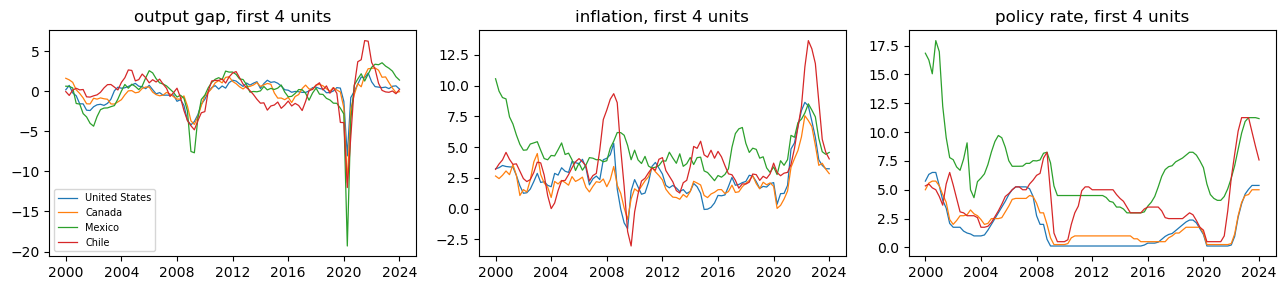

In [4]:
def hp_trend(y, lam=1600):
    n = len(y); D = np.zeros((n - 2, n))
    for i in range(n - 2): D[i, i:i + 3] = [1, -2, 1]
    return np.linalg.solve(np.eye(n) + lam * D.T @ D, y)

def one_sided_gap(series, lam=1600, min_len=16):
    '''HP gap using data through each quarter only (no look-ahead). Percent of trend.'''
    s = series.dropna(); y = np.log(s.values); out = pd.Series(np.nan, index=series.index)
    for t in range(min_len, len(y) + 1):
        out[s.index[t - 1]] = 100 * (y[t - 1] - hp_trend(y[:t], lam)[-1])
    return out

def hamilton_gap(series, h=8, p=4, min_len=16):
    '''Hamilton (2018) regression filter, re-estimated through each quarter. Percent.'''
    s = series.dropna(); y = np.log(s.values); out = pd.Series(np.nan, index=series.index)
    for t in range(max(min_len, h + p + 8), len(y) + 1):
        X = np.column_stack([np.ones(t - h - p + 1)] + [y[p - 1 - j: t - h - j] for j in range(p)])
        Yt = y[h + p - 1: t]
        beta = np.linalg.lstsq(X, Yt, rcond=None)[0]
        out[s.index[t - 1]] = 100 * (Yt[-1] - X[-1] @ beta)
    return out

gap_fn = {"hp1": one_sided_gap, "hamilton": hamilton_gap}[GAP_METHOD]
gap  = gdp.apply(gap_fn)                 # output gap, percent
infl = cpi if CPI_IS_RATE else 400 * np.log(cpi).diff()      # percent: year-on-year rates as given, or annualised q/q
rate_q = rate                            # policy rate, percent (quarterly average)

last = max(x.index.max() for x in (gap, infl, rate_q))
idx_all = pd.period_range(START, last, freq="Q")
present = {u: np.all([x.reindex(idx_all)[u].notna().values for x in (gap, infl, rate_q)], axis=0)
           for u in UNITS if all(u in x.columns for x in (gap, infl, rate_q))}
units = [u for u, ok in present.items() if ok[0]]                                  # complete at START
run_end = {u: idx_all[np.argmin(present[u]) - 1] if not present[u].all() else idx_all[-1] for u in units}
end = pd.Period(END, freq="Q") if END else min(run_end.values())
idx = pd.period_range(START, end, freq="Q")
panel = {v: x.reindex(idx) for v, x in zip(VARS, (gap, infl, rate_q))}
dropped = [u for u in UNITS if u not in units]
Z_raw = np.stack([np.stack([panel[v][u].values for v in VARS], axis=1) for u in units])   # (units, quarters, 3)
n_units, T = Z_raw.shape[:2]
at_zlb = Z_raw[:, :, 2] <= ZLB_THRESHOLD
first = idx.get_loc(pd.Period(FIRST_ORIGIN, freq="Q"))

print(f"Panel: {n_units} units x {T} quarters ({idx[0]} to {idx[-1]}), gap method = {GAP_METHOD}" + ("   [DEMO]" if DEMO else ""))
print(f"Training window at the first origin: {first + 1} quarters; forecast quarters: {T - first - 1}")
print(f"Share of unit-quarters at the zero lower bound: {at_zlb.mean():.1%}")
if dropped: print("Not complete from START, dropped:", dropped)
print("\nStandard deviation of each variable across quarters, summarised over units:")
print(pd.DataFrame({v: Z_raw[:, :, k].std(1) for k, v in enumerate(VARS)}, index=units).describe().loc[["mean", "min", "max"]].round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
for k, v in enumerate(VARS):
    ax[k].plot(idx.to_timestamp(), Z_raw[:4, :, k].T, lw=0.9)
    ax[k].set_title(f"{v}, first 4 units" + (" [DEMO]" if DEMO else ""))
ax[0].legend(units[:4], fontsize=7); plt.tight_layout(); plt.show()

## 4. Two estimators of the structural parameters
**Maximum likelihood.** Gaussian likelihood of the restricted VAR(1) through three moment matrices, optimised in an
unconstrained space mapped to wide bounds, three starts per unit. No prior.

**Neural (amortised) estimator.** Trained once on `N_SIM` simulated economies drawn from the population bounds,
each compressed into 18 summary statistics. Two differences from the Monte Carlo notebook:

* The simulated samples have the **median training-window length** of the rolling loop, not 160 quarters, so the
  noise level in the summary statistics matches what the network sees at prediction time.
* A **range check** reports, feature by feature, the share of real units whose summary statistics fall outside the
  1st to 99th percentile of the training set. Non-trivial shares mean the network is extrapolating. The fix is to
  widen `LO`/`HI` in the setup cell and re-run; this is the mis-centred-prior risk made concrete.

In [5]:
WLO = np.array([0.2, 0.005, 1.01, 0.0, 0.0, 0.0, 0.0, 0.01, 0.01, 0.01])
WHI = np.array([10., 1.5, 5.0, 3.0, 0.99, 0.99, 0.99, 3.0, 3.0, 3.0])
to_theta = lambda u: WLO + (WHI - WLO) / (1 + np.exp(-u))
from_theta = lambda th: np.log((th - WLO) / (WHI - th))

def negll(u, S11, S10, S00, n):
    try:
        Phi, Om = var_form(to_theta(u)); Phi, Om = Phi[0], Om[0]
        S = S11 - Phi @ S10.T - S10 @ Phi.T + Phi @ S00 @ Phi.T
        sign, ld = np.linalg.slogdet(Om)
        val = 0.5 * n * (ld + np.trace(np.linalg.solve(Om, S)))
    except np.linalg.LinAlgError:
        return 1e10
    return val if (np.isfinite(val) and sign > 0) else 1e10

def mle(Zi, rng, n_starts=3):
    Z0, Z1 = Zi[:-1], Zi[1:]; n = len(Z0)
    args = (Z1.T @ Z1 / n, Z1.T @ Z0 / n, Z0.T @ Z0 / n, n)
    best = None
    for th0 in [(LO + HI) / 2] + list(draw_theta(n_starts - 1, rng)):
        r = minimize(negll, from_theta(th0), args=args, method="L-BFGS-B", bounds=[(-12, 12)] * 10)
        if best is None or r.fun < best.fun: best = r
    return to_theta(best.x)

def summary_stats(Z):
    '''Per-unit unrestricted VAR(1) + volatilities. Returns (features, Phi_ols).'''
    Z0, Z1 = Z[:, :-1], Z[:, 1:]
    S00 = np.einsum("nti,ntj->nij", Z0, Z0); S10 = np.einsum("nti,ntj->nij", Z1, Z0)
    Phi = np.linalg.solve(S00, S10.transpose(0, 2, 1)).transpose(0, 2, 1)
    E = Z1 - np.einsum("nij,ntj->nti", Phi, Z0)
    Om = np.einsum("nti,ntj->nij", E, E) / E.shape[1]
    sd = np.sqrt(np.einsum("nii->ni", Om)); C = Om / (sd[:, :, None] * sd[:, None, :])
    F = np.hstack([Phi.reshape(len(Z), 9), np.log(sd), C[:, [0, 0, 1], [1, 2, 2]], np.log(Z.std(axis=1))])
    return F, Phi

T_NN = (first + 1 + T) // 2            # median training-window length of the rolling loop
t0 = time.time(); rng_nn = np.random.default_rng(SEED + 1)
theta_sim = draw_theta(N_SIM, rng_nn)
F_sim, _ = summary_stats(simulate(theta_sim, T_NN, rng_nn))
nn = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(256, 256), early_stopping=True,
                                                           max_iter=300, random_state=SEED)),
    transformer=StandardScaler()).fit(F_sim, theta_sim)
print(f"Neural estimator trained on {N_SIM:,} simulated economies of {T_NN} quarters in {time.time() - t0:.0f}s")

# Range check: are the real units inside the region the network was trained on?
Ztr0 = Z_raw[:, :first + 1]; F_real, _ = summary_stats(Ztr0 - Ztr0.mean(1, keepdims=True))
lo, hi = np.percentile(F_sim, [1, 99], axis=0)
FEATS = ([f"Phi[{i},{j}]" for i in range(3) for j in range(3)] + ["log sd e_x", "log sd e_pi", "log sd e_r",
         "corr(e_x,e_pi)", "corr(e_x,e_r)", "corr(e_pi,e_r)", "log sd x", "log sd pi", "log sd r"])
outside = pd.Series(((F_real < lo) | (F_real > hi)).mean(0), index=FEATS)
print("\nShare of units outside the training range at the first origin (large = widen LO/HI and retrain):")
print(outside[outside > 0].round(2).to_string() if (outside > 0).any() else "  none")

Neural estimator trained on 40,000 simulated economies of 72 quarters in 73s

Share of units outside the training range at the first origin (large = widen LO/HI and retrain):
log sd e_x        0.45
log sd e_pi       0.05
log sd e_r        0.85
corr(e_pi,e_r)    0.95
log sd r          0.05


## 5. Rolling forecasting horse race
At each origin (every `REFIT_EVERY` quarters from `FIRST_ORIGIN`) the loop:

1. centres the panel on the **training-window means** only;
2. re-estimates the unrestricted VAR, the DSGE by MLE and the DSGE by the neural net on data through the origin;
3. refits every ML model on the same window;
4. produces one-quarter-ahead forecasts for the next `REFIT_EVERY` quarters, each using the actual lagged data.

Models are the same eight as in the Monte Carlo notebook. Features are lagged only: two own lags, two lags of the
cross-unit averages, and (pooled boosting only) the unit's training-sample VAR coefficients as an identity embedding.
The regularised boosting's minimum leaf size scales with the panel so that a leaf still spans about 40 quarters.
Forecast **errors** are stored, since the centring differs by origin while errors do not.

In [6]:
gb = lambda **kw: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, random_state=SEED,
                                                **{"max_iter": 300, **kw})
MODELS = ["No change", "Unrestricted VAR", "DSGE (MLE)", "DSGE (neural net)", "Pooled gradient boosting",
          "Hybrid: DSGE + naive boosting", "Hybrid: DSGE + regularised boosting", "Hybrid: DSGE + country ridge"]

def features(Zc, use_global=True):
    '''Lag-only features from a centred panel (units, T, 3). Index k of every output refers to quarter k + 2.'''
    Y, L1, L2 = Zc[:, 2:], Zc[:, 1:-1], Zc[:, :-2]
    G = Zc.mean(0); G1 = np.broadcast_to(G[1:-1], L1.shape); G2 = np.broadcast_to(G[:-2], L1.shape)
    base = np.concatenate([L1, L2, G1, G2] if use_global else [L1, L2], axis=2)
    ridge_x = np.concatenate([L1, G1] if use_global else [L1], axis=2)
    return Y, L1, base, ridge_x

def run_race(Z_raw, use_global=True, verbose=True):
    '''Expanding-window one-quarter-ahead forecasts. Returns {model: errors (units, T, 3)} and the parameter paths.'''
    n, T = Z_raw.shape[:2]
    err = {m: np.full((n, T, 3), np.nan) for m in MODELS}
    path = {"mle": [], "nn": [], "origin": []}
    rng_mle = np.random.default_rng(SEED + 2); t0 = time.time(); flat = lambda a: a.reshape(-1, a.shape[-1])
    for o in range(first, T - 1, REFIT_EVERY):
        mu = Z_raw[:, :o + 1].mean(1, keepdims=True)                   # training-window means only
        Zc = Z_raw - mu
        Y, L1, base, Xr = features(Zc, use_global)
        tr = slice(0, o - 1)                                            # targets at quarters 2 .. o
        te = slice(o - 1, min(o - 1 + REFIT_EVERY, Y.shape[1]))         # targets at quarters o+1 .. o+k
        q = slice(te.start + 2, te.stop + 2)                            # the quarters being forecast
        # reduced-form and structural estimates on data through the origin
        F, Phi_ols = summary_stats(Zc[:, :o + 1])
        th_nn = np.clip(nn.predict(F), WLO + 1e-3, WHI - 1e-3)
        th_mle = np.array([mle(Zc[i, :o + 1], rng_mle) for i in range(n)])
        path["mle"].append(th_mle); path["nn"].append(th_nn); path["origin"].append(idx[o])
        Phi = {"Unrestricted VAR": Phi_ols, "DSGE (MLE)": var_form(th_mle)[0], "DSGE (neural net)": var_form(th_nn)[0]}
        pred = {"No change": L1[:, te]}
        pred.update({m: np.einsum("nij,ntj->nti", P, L1[:, te]) for m, P in Phi.items()})
        # machine-learning models fitted on the same window
        dsge_all = np.einsum("nij,ntj->nti", Phi["DSGE (MLE)"], L1); resid = Y - dsge_all
        Xp = np.concatenate([base, np.broadcast_to(Phi_ols.reshape(n, 1, 9), (n, base.shape[1], 9))], axis=2)
        fitpred = lambda model, X, y: model.fit(flat(X[:, tr]), y[:, tr].ravel()).predict(flat(X[:, te])).reshape(n, -1)
        n_rows = n * (tr.stop - tr.start); leaf = int(min(40 * n, 0.5 * n_rows))       # about 40 quarters per leaf
        p_pool, p_naive, p_reg, p_ridge = (np.empty(Y[:, te].shape) for _ in range(4))
        for k in range(3):
            p_pool[:, :, k] = fitpred(gb(), Xp, Y[:, :, k])
            p_naive[:, :, k] = dsge_all[:, te, k] + fitpred(gb(), base, resid[:, :, k])
            p_reg[:, :, k] = dsge_all[:, te, k] + fitpred(gb(min_samples_leaf=leaf, max_iter=150), base, resid[:, :, k])
        for i in range(n):
            p_ridge[i] = dsge_all[i, te] + RidgeCV(alphas=np.logspace(-2, 3, 12)).fit(Xr[i, tr], resid[i, tr]).predict(Xr[i, te])
        pred.update({"Pooled gradient boosting": p_pool, "Hybrid: DSGE + naive boosting": p_naive,
                     "Hybrid: DSGE + regularised boosting": p_reg, "Hybrid: DSGE + country ridge": p_ridge})
        for m in MODELS: err[m][:, q] = pred[m] - Y[:, te]
        if verbose: print(f"origin {idx[o]}: forecast {idx[q.start]} to {idx[q.stop - 1]}   [{time.time() - t0:.0f}s]")
    return err, path

err, path = run_race(Z_raw)

origin 2011Q4: forecast 2012Q1 to 2012Q4   [9s]
origin 2012Q4: forecast 2013Q1 to 2013Q4   [22s]
origin 2013Q4: forecast 2014Q1 to 2014Q4   [32s]
origin 2014Q4: forecast 2015Q1 to 2015Q4   [44s]
origin 2015Q4: forecast 2016Q1 to 2016Q4   [56s]
origin 2016Q4: forecast 2017Q1 to 2017Q4   [68s]
origin 2017Q4: forecast 2018Q1 to 2018Q4   [79s]
origin 2018Q4: forecast 2019Q1 to 2019Q4   [90s]
origin 2019Q4: forecast 2020Q1 to 2020Q4   [101s]
origin 2020Q4: forecast 2021Q1 to 2021Q4   [110s]
origin 2021Q4: forecast 2022Q1 to 2022Q4   [119s]
origin 2022Q4: forecast 2023Q1 to 2023Q4   [129s]
origin 2023Q4: forecast 2024Q1 to 2024Q1   [138s]


## 6. Scoring
RMSE per variable and on average, then each model against the unrestricted VAR and against the no-change forecast
with a **panel Diebold-Mariano test**: the squared-loss differential is averaged across units in each quarter (which absorbs the cross-sectional
correlation of a common shock) and the resulting time series is tested with the Harvey-Leybourne-Newbold
correction. A negative statistic means the model beats the VAR.

One-quarter-ahead RMSE over 980 unit-quarters, 2012Q1 to 2024Q1
                                     output gap  inflation  policy rate  average
Pooled gradient boosting                  1.776      1.348        0.457    1.194
No change                                 2.197      1.067        0.435    1.233
Hybrid: DSGE + naive boosting             2.259      1.151        0.389    1.267
Unrestricted VAR                          2.169      1.233        0.541    1.314
DSGE (neural net)                         2.040      1.187        0.799    1.342
Hybrid: DSGE + regularised boosting       2.225      1.317        0.508    1.350
Hybrid: DSGE + country ridge              2.199      1.351        0.573    1.374
DSGE (MLE)                                2.222      1.374        0.571    1.389

Diebold-Mariano statistic against the unrestricted VAR (negative = better than the VAR)
                                         output gap       inflation     policy rate
No change                         

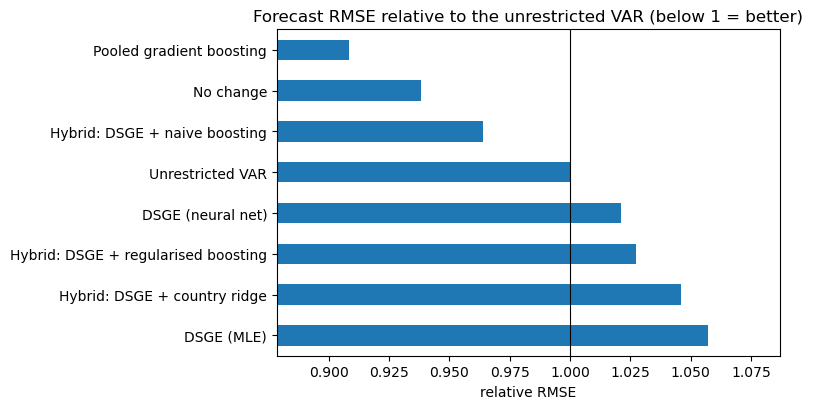

In [7]:
scored = ~np.isnan(err["No change"][:, :, 0])            # (units, quarters) that were actually forecast

def rmse_table(err, mask):
    rows = {m: np.sqrt(np.nanmean(np.where(mask[:, :, None], err[m], np.nan) ** 2, axis=(0, 1))) for m in MODELS}
    out = pd.DataFrame(rows, index=VARS).T; out["average"] = out.mean(1)
    return out.sort_values("average")

def dm_test(e_model, e_bench, mask):
    '''Panel Diebold-Mariano, one step ahead. Negative statistic = model beats benchmark.'''
    d = np.where(mask, e_model ** 2 - e_bench ** 2, np.nan)
    dt = np.nanmean(d, axis=0); dt = dt[~np.isnan(dt)]; n = len(dt)
    dbar, se = dt.mean(), np.sqrt(dt.var(ddof=1) / n)
    stat = dbar / se * np.sqrt((n - 1) / n)                 # Harvey-Leybourne-Newbold, h = 1
    return stat, 2 * tdist.sf(abs(stat), df=n - 1)

def dm_table(err, mask, bench="Unrestricted VAR"):
    rows = {}
    for m in MODELS:
        if m == bench: continue
        rows[m] = {v: "{:+.2f} (p={:.2f})".format(*dm_test(err[m][:, :, k], err[bench][:, :, k], mask)) for k, v in enumerate(VARS)}
    return pd.DataFrame(rows).T

race = rmse_table(err, scored)
tag = "   [DEMO DATA]" if DEMO else ""
print(f"One-quarter-ahead RMSE over {scored.sum()} unit-quarters, {idx[np.where(scored.any(0))[0][0]]} to {idx[-1]}{tag}")
print(race.round(3).to_string())
print("\nDiebold-Mariano statistic against the unrestricted VAR (negative = better than the VAR)" + tag)
print(dm_table(err, scored).to_string())
print("\nDiebold-Mariano statistic against the no-change forecast (negative = better than no change)" + tag)
print(dm_table(err, scored, bench="No change").to_string())

rel = race["average"] / race.loc["Unrestricted VAR", "average"]
ax = rel.plot.barh(figsize=(8, 4.2)); ax.axvline(1, color="k", lw=0.8); ax.invert_yaxis()
ax.set(title="Forecast RMSE relative to the unrestricted VAR (below 1 = better)" + tag, xlabel="relative RMSE",
       xlim=(rel.min() - 0.03, rel.max() + 0.03))
plt.tight_layout(); plt.show()

### How stable are the structural estimates as the window grows?
Median estimate across units at each forecast origin. Large swings in MLE with a flat neural-net line are the
real-data version of the "flat likelihood" blow-ups seen in the Monte Carlo study.

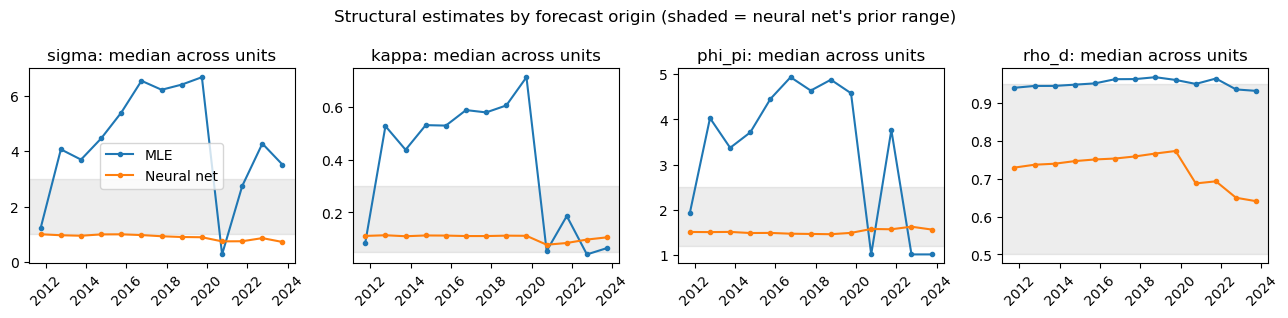

In [8]:
origins = [o.to_timestamp() for o in path["origin"]]
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, p in zip(ax, [0, 1, 2, 4]):
    for key, lab in [("mle", "MLE"), ("nn", "Neural net")]:
        a.plot(origins, np.median(np.array(path[key])[:, :, p], axis=1), marker="o", ms=3, label=lab)
    a.axhspan(LO[p], HI[p], color="k", alpha=0.07); a.set_title(f"{NAMES[p]}: median across units"); a.tick_params(axis="x", rotation=45)
ax[0].legend(); plt.suptitle("Structural estimates by forecast origin (shaded = neural net's prior range)" + tag)
plt.tight_layout(); plt.show()

## 7. Robustness
**(a) Zero lower bound.** The Taylor rule cannot hold while the rate is pinned at zero, so the DSGE is misspecified
there by construction. Re-score excluding unit-quarters where the rate was at the bound in the quarter before the
forecast. A cleaner alternative is to replace the policy rate by a shadow rate (Wu-Xia, Krippner) where one exists.

**(b) Cross-country averages.** Re-run the whole race with own lags only in the ML features. If the hybrids lose
their edge, the common-shock channel is what they were repairing, which is the World B diagnostic on real data.

In [9]:
lag_zlb = np.zeros_like(at_zlb); lag_zlb[:, 1:] = at_zlb[:, :-1]
mask_nozlb = scored & ~lag_zlb
print(f"(a) Excluding {scored.sum() - mask_nozlb.sum()} of {scored.sum()} unit-quarters at the zero lower bound" + tag)
print(rmse_table(err, mask_nozlb).round(3).to_string())

if RUN_ROBUSTNESS:
    err_local, _ = run_race(Z_raw, use_global=False, verbose=False)
    cmp = pd.DataFrame({"with cross-country averages": race["average"],
                        "own lags only": rmse_table(err_local, scored)["average"]})
    cmp["change"] = cmp["own lags only"] - cmp["with cross-country averages"]
    print("\n(b) Average RMSE with and without cross-country averages in the ML features (DSGE and VAR rows are unaffected)" + tag)
    print(cmp.round(3).to_string())

(a) Excluding 500 of 980 unit-quarters at the zero lower bound
                                     output gap  inflation  policy rate  average
Hybrid: DSGE + naive boosting             2.106      1.265        0.504    1.292
No change                                 2.004      1.300        0.603    1.302
Pooled gradient boosting                  1.668      1.709        0.626    1.334
Hybrid: DSGE + regularised boosting       2.071      1.409        0.676    1.385
Unrestricted VAR                          2.001      1.480        0.681    1.387
DSGE (neural net)                         1.895      1.349        0.948    1.397
DSGE (MLE)                                2.060      1.436        0.765    1.420
Hybrid: DSGE + country ridge              2.066      1.507        0.734    1.436

(b) Average RMSE with and without cross-country averages in the ML features (DSGE and VAR rows are unaffected)
                                     with cross-country averages  own lags only  change
DSGE (ML

## 8. Checklist and next steps
1. **Decide what to do with the shared-rate units.** Nine of the 20 units carry the ECB rate. Compare this run with
   `EXCLUDE_SHARED_RATE_UNITS = True`: if the hybrids' gains concentrate in the euro units, they are learning the ECB's
   common reaction, not country dynamics.
2. **Read the range check** in Section 4. If several features show units outside the training range, widen
   `LO`/`HI` and re-run.
3. **Read the Diebold-Mariano table** before the RMSE ranking. With roughly 55 test quarters, differences of a
   few percent will often not be significant; say so in the write-up.
4. **Expect the plain DSGE to trail the VAR.** The model has no interest-rate smoothing, habit or indexation, so it
   implies less persistence than real data. The questions that remain interesting are whether the hybrids repair
   it, whether neural-net parameters forecast as well as MLE, and what happens in 2021 to 2023.
5. **Extensions.** Rate smoothing in the Taylor rule (needs a general linear rational-expectations solver, since
   the lagged rate becomes a state), shadow rates in place of the policy rate at the bound, and neural posterior
   estimation for parameter uncertainty.